# Week 9 Coding

**C1** checks the hand results of the problem set with your own short-time Fourier transform. **C2** builds a simplified song identifier. **C3** (optional) reads the heart rate from the wrist signal of the lecture.

**Predict first.** Before running any check cell, write down on paper what the output will be.

**How to work in this notebook.** Execute the cells in order with Shift+Enter. Each task has a cell with gaps marked `...`: fill them, run the cell, then execute the check cell below it. A passing check prints a confirmation; a failing one raises an `AssertionError`.

In [9]:
import numpy as np
import matplotlib.pyplot as plt

## C1: The hand results, checked (P2, P3, P4, P10)

Column $m$ of the short-time Fourier transform is the DFT of the window of $N_w$ samples that starts at $mH$:
$$X_m[k] = \sum_{n=0}^{N_w-1} x[mH + n]\, e^{-j2\pi kn/N_w}.$$

Complete `stft`, which returns a matrix whose column $m$ contains $X_m[0], \dots, X_m[N_w - 1]$, for every window that fits entirely in the signal. Use `np.fft.fft`. Then enter the results of P3 computed by hand; complex numbers are written as `-3 + 1j`.

In [10]:
def stft(x, Nw, H):
    """Columns X_m[k], k = 0..Nw-1, of every window of Nw samples that fits in x; windows start every H samples."""
    starts = np.arange(0, len(x) - Nw + 1, H)                                                   # your code: the start mH of every window that fits
    return np.array([np.fft.fft(x[s:s + Nw]) for s in starts]).T                       # your code: the DFT of each window

x_P3 = np.array([2, 0, -2, 0, 1, 1, 1, 1])
X0_P3 = np.array([0, 4, 0, 4])                                            # P3 a): X_0[k], k = 0..3
X1_P3 = np.array([4, 0, 0, 0])                                            # P3 a): X_1[k]
Xmid_P3 = np.array([0, -3+1j, -2, -3-1j])                                          # P3 c): the window starting at n = 2

In [11]:
S = stft(x_P3, 4, 4)
assert S.shape == (4, 2), "two windows of 4 samples fit in 8 samples with H = 4"
assert np.allclose(S[:, 0], X0_P3) and np.allclose(S[:, 1], X1_P3), "P3 a)"
assert np.allclose(stft(x_P3, 4, 2)[:, 1], Xmid_P3), "P3 c)"
x = np.zeros(4000); x[2001] = 1                                    # P2: one impulse, Nw = 256, H = 64
A = np.abs(stft(x, 256, 64)); hit = np.flatnonzero(A.max(axis=0) > 0)
assert len(hit) == 4 and np.allclose(A[:, hit], 1), "P2"
x = np.random.default_rng(0).standard_normal(3000)                 # P4: delay by 200 samples, H = 100
y = np.r_[np.zeros(200), x][:3000]
Ax, Ay = np.abs(stft(x, 400, 100)), np.abs(stft(y, 400, 100))
assert np.allclose(Ay[:, 2:], Ax[:, :Ay.shape[1] - 2]), "P4"
E = lambda H: np.sum(np.abs(stft(x_P3, 4, H))**2)                   # P10
assert np.isclose(E(4), 48) and np.isclose(E(2), 72), "P10"
print("C1 passed: P3 by hand agrees with stft; P2 gives four flat columns, P4 moves the image by two columns, P10 gives 48 and 72.")

C1 passed: P3 by hand agrees with stft; P2 gives four flat columns, P4 moves the image by two columns, P10 gives 48 and 72.


## C2: A Simplified Song Identifier

This task builds, in four steps, a simplified version of the method used by song-identification services: from a noisy clip of 5 s, find the song in a small database and the time at which the clip starts. It connects the whole week: the spectrogram (Video 2), the choice of the window (Video 3) and the peaks of the spectrogram (Video 4).

The steps: **a)** the spectrogram, **b)** fingerprints from pairs of peaks, **c)** matching by votes, **d)** experiments with the noise level and the window length. The peak detection and the database of melodies are given.

### The database: five melodies

Five public-domain melodies are synthesized at $f_s = 8000$ Hz. Every note is a sum of four harmonics with a decaying envelope; each melody has its own key, tempo and harmonic amplitudes, as different recordings would. Run the cell and listen to one melody.

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
from scipy.ndimage import maximum_filter
from IPython.display import Audio

fs = 8000

def note_freq(name, shift):
    """Frequency of a note such as 'E4', transposed by shift semitones (A4 = 440 Hz)."""
    steps = {'C': -9, 'D': -7, 'E': -5, 'F': -4, 'G': -2, 'A': 0, 'B': 2}
    return 440 * 2**((steps[name[0]] + 12*(int(name[-1]) - 4) + shift) / 12)

def note(f, dur, amps):
    t = np.arange(int(round(dur * fs))) / fs
    env = np.exp(-2*t)
    nf = int(0.01 * fs)
    env[:nf] *= np.linspace(0, 1, nf)
    env[-nf:] *= np.linspace(1, 0, nf)
    return env * sum(a * np.cos(2*np.pi*(m + 1)*f*t) for m, a in enumerate(amps))

def parse(s):
    """'E4 D4:2' -> [('E4', 1.0), ('D4', 2.0)]: note and length in beats."""
    return [(tok.split(':')[0], float(tok.split(':')[1]) if ':' in tok else 1.0) for tok in s.split()]

SONGS = {   # melody, beat (s), transposition (semitones), harmonic amplitudes
    "Ode to Joy": (parse("E4 E4 F4 G4 G4 F4 E4 D4 C4 C4 D4 E4 E4:1.5 D4:0.5 D4:2 E4 E4 F4 G4 G4 F4 E4 D4 C4 C4 D4 E4 D4:1.5 C4:0.5 C4:2"), 0.45, 2, (1, .5, .3, .2)),
    "Frere Jacques": (parse("C4 D4 E4 C4 C4 D4 E4 C4 E4 F4 G4:2 E4 F4 G4:2 G4:0.5 A4:0.5 G4:0.5 F4:0.5 E4 C4 G4:0.5 A4:0.5 G4:0.5 F4:0.5 E4 C4 C4 G3 C4:2 C4 G3 C4:2"), 0.35, -3, (1, .2, .6, .1)),
    "Twinkle Twinkle": (parse("C4 C4 G4 G4 A4 A4 G4:2 F4 F4 E4 E4 D4 D4 C4:2 G4 G4 F4 F4 E4 E4 D4:2 G4 G4 F4 F4 E4 E4 D4:2"), 0.4, 0, (1, .7, .2, .4)),
    "Au clair de la lune": (parse("C4 C4 C4 D4 E4:2 D4:2 C4 E4 D4 D4 C4:4 C4 C4 C4 D4 E4:2 D4:2 C4 E4 D4 D4 C4:4"), 0.38, 5, (1, .3, .3, .05)),
    "Mary Had a Little Lamb": (parse("E4 D4 C4 D4 E4 E4 E4:2 D4 D4 D4:2 E4 G4 G4:2 E4 D4 C4 D4 E4 E4 E4 E4 D4 D4 E4 D4 C4:4"), 0.32, -5, (1, .5, .5, .3)),
}
audio = {name: np.concatenate([note(note_freq(n, shift), beats*beat, amps) for n, beats in melody])
         for name, (melody, beat, shift, amps) in SONGS.items()}
for name, x in audio.items():
    print(f"{name:24s} {len(x)/fs:5.1f} s")
Audio(audio["Ode to Joy"], rate=fs)

Ode to Joy                14.4 s
Frere Jacques             11.2 s
Twinkle Twinkle           12.8 s
Au clair de la lune       12.2 s
Mary Had a Little Lamb    10.2 s


### a) The spectrogram

Column $m$ of the spectrogram is the DFT of the window of $N_w$ samples starting at $mH$, as on the slides:
$$X_m[k] = \sum_{n=0}^{N_w-1} x[mH + n]\, e^{-jk\frac{2\pi}{N_w} n}.$$

Complete `spectrogram_db`, which returns $20\log_{10}\lvert X_m[k]\rvert$ for $k = 0, \dots, N_w/2$ (rows) and all windows that fit in the signal (columns). Use `np.fft.rfft`, which returns exactly the bins $0, \dots, N_w/2$.

Before running the check cell, compute $\Delta t$ and $\Delta f$ for $N_w = 1024$. The shortest note of the database lasts $0.175$ s, and two different notes of the same melody are at least $16.5$ Hz apart. Does this window resolve both?

In [15]:
def spectrogram_db(x, Nw=1024, H=256):
    """Magnitude of the STFT in dB: rows are the bins 0..Nw/2, columns the windows."""
    starts = np.arange(0, len(x) - Nw + 1, H)                                                   # your code: the start of every window that fits
    X = np.array([np.fft.rfft(x[s:s + Nw]) for s in starts]).T                          # your code: the DFT of each window
    return 20 * np.log10(np.abs(X) + 1e-9)

In [16]:
t = np.arange(fs) / fs
S = spectrogram_db(np.cos(2*np.pi*1000*t))                        # 1 s of a 1000 Hz tone
assert S.shape == (513, 28)                                        # 513 bins, (8000 - 1024) // 256 + 1 = 28 columns
assert np.all(np.argmax(S, axis=0) == 128)                         # 1000 Hz = bin 1000 * 1024 / 8000
Nw = 1024
assert Nw / fs < 0.175 and fs / Nw < 16.5                          # Delta t = 0.128 s, Delta f = 7.8 Hz
print("a) passed: the 1000 Hz tone is in bin 128; N_w = 1024 gives Delta t = 0.128 s and Delta f = 7.8 Hz.")

a) passed: the 1000 Hz tone is in bin 128; N_w = 1024 gives Delta t = 0.128 s and Delta f = 7.8 Hz.


### The peaks (given)

Only the strongest local maxima of the spectrogram are kept: a point is a peak if it is the largest value in a neighbourhood of 21 bins by 11 columns, and at most 15 peaks per second are retained. The function returns the peaks as pairs (column, bin), sorted by time. Run the cell: the peaks of a clip lie on the harmonics of the notes.

120 peaks


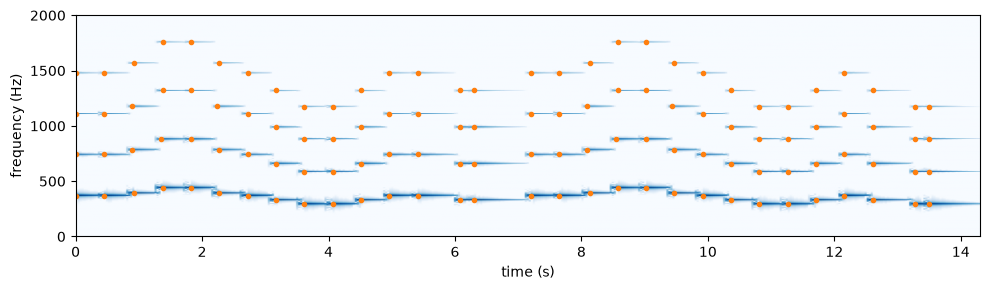

In [17]:
def peaks(S, H=256, per_sec=15):
    """Strongest local maxima of a spectrogram in dB, as a time-sorted list of (column, bin)."""
    is_max = (S == maximum_filter(S, size=(21, 11))) & (S > S.max() - 50)
    k, m = np.nonzero(is_max)
    n_keep = int(per_sec * S.shape[1] * H / fs)
    order = np.argsort(S[k, m])[::-1][:n_keep]
    return sorted(zip(m[order], k[order]))

S = spectrogram_db(audio["Ode to Joy"])
P = peaks(S)
plt.figure(figsize=(10, 3))
plt.imshow(S, origin="lower", aspect="auto", cmap="Blues", vmin=S.max() - 30,
           extent=[0, S.shape[1]*256/fs, 0, fs/2])
plt.plot([m*256/fs for m, k in P], [k*fs/1024 for m, k in P], "o", ms=3, color="tab:orange")
plt.ylim(0, 2000); plt.xlabel("time (s)"); plt.ylabel("frequency (Hz)"); plt.tight_layout()
print(len(P), "peaks")

### b) Fingerprints from pairs of peaks

A single peak, one frequency at one time, is not distinctive: the same note occurs many times, in many melodies. A pair of peaks is. Each peak $(t_1, f_1)$ is paired with the next `fan` peaks $(t_2, f_2)$ that follow it within `dmax` columns, and the pair gives the entry
$$\text{key} = (f_1,\ f_2,\ t_2 - t_1), \qquad \text{time} = t_1.$$
The key contains the time **difference**, not the times themselves, since a clip may start anywhere in the song.

Complete `fingerprints`. Before running the check cell, write down the output for the three peaks `[(0, 10), (2, 20), (5, 30)]` with `fan=2`.

In [19]:
def fingerprints(P, fan=10, dmax=50):
    """List of (key, t1) with key = (f1, f2, t2 - t1), for the peaks P = [(t, f), ...] sorted by time."""
    out = []
    for i, (t1, f1) in enumerate(P):
        paired = 0
        for t2, f2 in P[i + 1:]:
            if t2 - t1 > dmax:
                break
            if t2 == t1:
                continue
            out.append(((f1, f2, t2 - t1), t1))                                        # your code: the entry (key, t1)
            paired += 1
            if paired == fan:
                break
    return out

In [20]:
assert fingerprints([(0, 10), (2, 20), (5, 30)], fan=2) == [((10, 20, 2), 0), ((10, 30, 5), 0), ((20, 30, 3), 2)]

database = defaultdict(list)                                       # key -> list of (song, t1)
for name, x in audio.items():
    for key, t1 in fingerprints(peaks(spectrogram_db(x))):
        database[key].append((name, t1))
print("b) passed:", sum(len(v) for v in database.values()), "entries in the database.")

b) passed: 4863 entries in the database.


### c) Matching by votes

For every fingerprint of the clip whose key is in the database, each stored entry (song, $t_\text{song}$) votes for the pair (song, $t_\text{song} - t_\text{clip}$). If the clip comes from a song and starts at column $m_0$ of it, all its matching entries vote for the same pair (song, $m_0$), whereas accidental matches spread their votes over many offsets.

Complete `identify`, which returns the song and the offset with the most votes, the offset in seconds, and the number of votes.

In [22]:
def identify(clip):
    votes = Counter()
    for key, t_clip in fingerprints(peaks(spectrogram_db(clip))):
        for name, t_song in database.get(key, []):
            votes[(name, t_song - t_clip)] += 1                                                  # your code: one vote for (name, t_song - t_clip)
    (name, offset), n = votes.most_common(1)[0]
    return name, offset * 256 / fs, n

def make_clip(name, start, snr_db, seed=0, dur=5.0, gain=0.3):
    """A clip of dur seconds from a song, at another volume, with white noise at the given SNR."""
    rng = np.random.default_rng(seed)
    x = gain * audio[name][int(start*fs):int((start + dur)*fs)]
    noise = rng.standard_normal(len(x))
    noise *= np.sqrt(np.mean(x**2) / np.mean(noise**2)) / 10**(snr_db/20)
    return x + noise

clip = make_clip("Ode to Joy", start=6.0, snr_db=0)               # noise as strong as the music
print(identify(clip))
Audio(clip, rate=fs)

('Ode to Joy', np.float64(6.016), 44)


In [23]:
name, t0, n = identify(clip)
assert name == "Ode to Joy" and abs(t0 - 6.0) <= 0.032            # the start, to within one hop
results = [identify(make_clip(s, start=2.0, snr_db=0, seed=1))[0] for s in audio]
assert results == list(audio)
print(f"c) passed: '{name}', starting at {t0:.2f} s, with {n} votes; all five songs identified at 0 dB.")

c) passed: 'Ode to Joy', starting at 6.02 s, with 44 votes; all five songs identified at 0 dB.


### d) Experiments

Run the cell below, which identifies 10 random clips of every song and reports how many are correct.

1. Lower `snr_db` to $-10$ dB and listen to such a clip. How many clips are identified, and why do the peaks still work?
2. Set `Nw = 128` and then `Nw = 8192` (the database is rebuilt with the same window). Compute $\Delta t$ and $\Delta f$ for both, and explain the results with the time-frequency trade-off.
3. A clip that lies inside a repeated phrase may be found at the right song but at the start time of the other occurrence. Why?

In [24]:
snr_db = 0
Nw = 1024

def spectrogram_db_Nw(x):
    return spectrogram_db(x, Nw=Nw, H=Nw // 4)

database = defaultdict(list)
for name, x in audio.items():
    for key, t1 in fingerprints(peaks(spectrogram_db_Nw(x), H=Nw // 4)):
        database[key].append((name, t1))

rng = np.random.default_rng(3)
correct = 0
for name, x in audio.items():
    for trial in range(10):
        start = rng.uniform(0, len(x)/fs - 5.0)
        clip = make_clip(name, start, snr_db, seed=int(rng.integers(1_000_000)))
        votes = Counter()
        for key, t_clip in fingerprints(peaks(spectrogram_db_Nw(clip), H=Nw // 4)):
            for song, t_song in database.get(key, []):
                votes[(song, t_song - t_clip)] += 1
        correct += bool(votes) and votes.most_common(1)[0][0][0] == name
print(f"N_w = {Nw}, SNR = {snr_db} dB: {correct} of 50 clips identified")

N_w = 1024, SNR = 0 dB: 50 of 50 clips identified


## C3 (optional): The Heart Rate During Exercise

The file `data/wrist_bike_32hz.csv` contains the wrist PPG and the magnitude of the wrist acceleration of the lecture: ten minutes of cycling at high resistance, at $f_s = 32$ Hz. The file `data/ecg_beats.csv` contains the heartbeats detected in the chest ECG, which serve as the reference (Wrist PPG During Exercise, PhysioNet, Open Data Commons Attribution License).

The cell computes the spectrogram with your `stft` from C1, $N_w = 512$ ($16$ s) and $H = 32$ (one column per second), and the reference: the median heart rate of the ECG over the $16$ s of each window.

In [25]:
fs_w = 32
t_w, ppg, acc = np.loadtxt("data/wrist_bike_32hz.csv", delimiter=",", skiprows=1).T
beats = np.loadtxt("data/ecg_beats.csv", delimiter=",", skiprows=1)
Nw, H = 512, 32
S = np.abs(stft(ppg, Nw, H))[:Nw // 2 + 1]                        # rows k = 0..Nw/2
f = np.arange(Nw // 2 + 1) * fs_w / Nw
t_end = (np.arange(S.shape[1]) * H + Nw) / fs_w                   # each column uses the 16 s before t_end
ref = np.array([np.median(beats[(beats[:, 0] >= te - 16) & (beats[:, 0] < te), 1]) for te in t_end])

def report(hr, label):
    err = np.abs(hr - ref)
    print(f"{label}: mean error {err.mean():4.1f} bpm, {100 * np.mean(err > 10):3.0f} % of the readings off by more than 10 bpm")
    return err.mean()
print(S.shape[1], "columns, one per second")

574 columns, one per second


**a)** Complete `strongest`, which returns, for every column, the frequency of the largest magnitude between `lo` and `hi` hertz, in beats per minute. Run it between $0.7$ and $3.5$ Hz. Before running, recall the in-class session: which line will often be chosen during the first minutes?

**b)** Run it again between $1.2$ and $3.5$ Hz, a range that excludes the pedalling line near $1$ Hz.

In [26]:
def strongest(S, f, lo, hi):
    band = (f > lo) & (f < hi)
    return 60 * f[band][np.argmax(S[band], axis=0)]                                                    # your code: 60 times the frequency of the largest S within the band, per column

hr_a = strongest(S, f, 0.7, 3.5)
hr_b = strongest(S, f, 1.2, 3.5)
err_a, err_b = report(hr_a, "a) 0.7 to 3.5 Hz"), report(hr_b, "b) 1.2 to 3.5 Hz")

a) 0.7 to 3.5 Hz: mean error 19.2 bpm,  46 % of the readings off by more than 10 bpm
b) 1.2 to 3.5 Hz: mean error  7.6 bpm,  15 % of the readings off by more than 10 bpm


In [27]:
assert hr_a.shape == (S.shape[1],)
assert round(err_a) == 19 and round(err_b) == 8
print("a), b) passed: the plausible range reduces the mean error from 19 to 8 bpm.")

a), b) passed: the plausible range reduces the mean error from 19 to 8 bpm.


**c)** The heart rate changes by only a few beats per minute from one second to the next. Complete `track`: in every column, search only within `tol` beats per minute of the previous reading.

In [29]:
def track(S, f, lo=1.2, hi=3.5, tol=8):
    out, prev = [], None
    for m in range(S.shape[1]):
        band = (f > lo) & (f < hi)
        if prev is not None:
            band &= np.abs(60 * f - prev) <= tol                                            # your code: within tol bpm of prev
        prev = 60 * f[band][np.argmax(S[band, m])]
        out.append(prev)
    return np.array(out)

hr_c = track(S, f)
err_c = report(hr_c, "c) tracking")

c) tracking: mean error  2.7 bpm,   7 % of the readings off by more than 10 bpm


c) passed: the tracking follows the chest ECG with a mean error of 3 bpm.


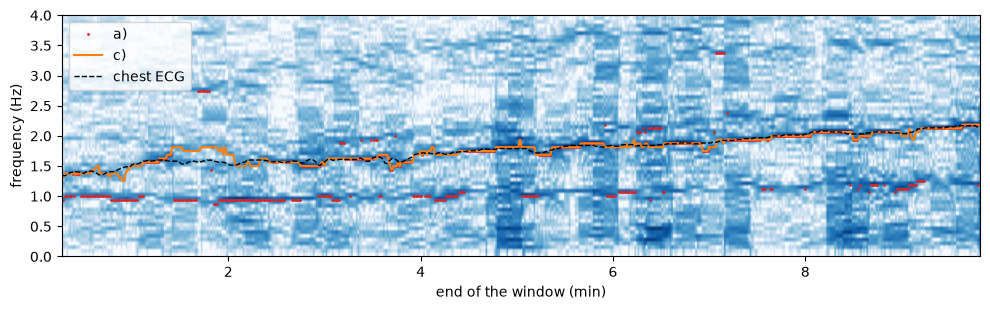

In [30]:
assert round(err_c) == 3
plt.figure(figsize=(10, 3.2))
plt.imshow(20 * np.log10(S + 1e-9), origin="lower", aspect="auto", cmap="Blues",
           vmin=20 * np.log10(S.max()) - 30, extent=[t_end[0] / 60, t_end[-1] / 60, 0, fs_w / 2])
plt.plot(t_end / 60, hr_a / 60, ".", ms=2, color="tab:red", label="a)")
plt.plot(t_end / 60, hr_c / 60, color="tab:orange", lw=1.5, label="c)")
plt.plot(t_end / 60, ref / 60, "k--", lw=1, label="chest ECG")
plt.ylim(0, 4); plt.xlabel("end of the window (min)"); plt.ylabel("frequency (Hz)"); plt.legend(loc="upper left")
plt.tight_layout()
print("c) passed: the tracking follows the chest ECG with a mean error of 3 bpm.")

**d)** Answer from the plot and the numbers:
1. Which lines does b) still choose instead of the heartbeat?
2. For which person would the range of b) fail?
3. What happens to c) if the first reading is wrong?

1. The second harmonic of the heartbeat (about $172$ bpm near the start, twice $86$ bpm) and the second harmonic of the pedalling, near $2$ Hz.
2. For a person whose heart rate is below $72$ bpm ($1.2$ Hz), for instance at rest or at the start of light exercise: the range then excludes the heartbeat itself. The range was chosen for this recording.
3. The tracking follows the line it started on: if this is the motion, it may follow the motion for the whole recording. Practical watches combine several of these rules, and use the accelerometer to identify the lines of the motion.